# Section 3: AI Platforms — From Raw Data to a Deployed Model

**Topics:** EDA · Missing Values · Outlier Detection · Encoding · Feature Engineering · Train/Test Split · ML Pipeline · Model Training · Cross-Validation · Hyperparameter Tuning · Evaluation · Model Artifact · REST API Deployment

## 1. Library Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute        import SimpleImputer, KNNImputer
from sklearn.preprocessing import (OrdinalEncoder, OneHotEncoder,
                                   StandardScaler, MinMaxScaler,
                                   RobustScaler, PowerTransformer)
from sklearn.model_selection import train_test_split
from scipy.ndimage           import gaussian_filter1d
from scipy.stats             import zscore

import warnings
warnings.filterwarnings('ignore')

## 2. Load the Dataset
We use the **House Price** dataset — tabular data describing city-level housing features with `price` as the regression target.

In [2]:
df = pd.read_csv('/content/House_Price.csv')
print(f'Shape: {df.shape}')
df.head()

Shape: (506, 19)


,price,crime_rate,resid_area,air_qual,room_num,age,dist1,dist2,dist3,dist4,teachers,poor_prop,airport,n_hos_beds,n_hot_rooms,waterbody,rainfall,bus_ter,parks
0,24.0,0.00632,32.31,0.538,6.575,65.2,4.35,3.81,4.18,4.01,24.7,4.98,YES,5.480,11.1920,River,23,YES,0.049347
1,21.6,0.02731,37.07,0.469,6.421,78.9,4.99,4.70,5.12,5.06,22.2,9.14,NO,7.332,12.1728,Lake,42,YES,0.046146
2,34.7,0.02729,37.07,0.469,7.185,61.1,5.03,4.86,5.01,4.97,22.2,4.03,NO,7.394,101.1200,NaN,38,YES,0.045764
3,33.4,0.03237,32.18,0.458,6.998,45.8,6.21,5.93,6.16,5.96,21.3,2.94,YES,9.268,11.2672,Lake,45,YES,0.047151
4,36.2,0.06905,32.18,0.458,7.147,54.2,6.16,5.86,6.37,5.86,21.3,5.33,NO,8.824,11.2896,Lake,55,YES,0.039474


## 3. Exploratory Data Analysis (EDA)

Understand the dataset:  
data types, size, statistics, and missing values.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   price        506 non-null    float64
 1   crime_rate   506 non-null    float64
 2   resid_area   506 non-null    float64
 3   air_qual     506 non-null    float64
 4   room_num     506 non-null    float64
 5   age          506 non-null    float64
 6   dist1        506 non-null    float64
 7   dist2        506 non-null    float64
 8   dist3        506 non-null    float64
 9   dist4        506 non-null    float64
 10  teachers     506 non-null    float64
 11  poor_prop    506 non-null    float64
 12  airport      506 non-null    object 
 13  n_hos_beds   498 non-null    float64
 14  n_hot_rooms  506 non-null    float64
 15  waterbody    351 non-null    object 
 16  rainfall     506 non-null    int64  
 17  bus_ter      506 non-null    object 
 18  parks        506 non-null    float64
dtypes: float

In [4]:
df.describe()

,price,crime_rate,resid_area,air_qual,room_num,age,dist1,dist2,dist3,dist4,teachers,poor_prop,n_hos_beds,n_hot_rooms,rainfall,parks
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,498.000000,506.000000,506.000000,506.000000
mean,22.528854,3.613524,41.136779,0.554695,6.284634,68.574901,3.971996,3.628775,3.960672,3.618972,21.544466,12.653063,7.899767,13.041605,39.181818,0.054454
std,9.182176,8.601545,6.860353,0.115878,0.702617,28.148861,2.108532,2.108580,2.119797,2.099203,2.164946,7.141062,1.476683,5.238957,12.513697,0.010632
min,5.000000,0.006320,30.460000,0.385000,3.561000,2.900000,1.130000,0.920000,1.150000,0.730000,18.000000,1.730000,5.268000,10.057600,3.000000,0.033292
25%,17.025000,0.082045,35.190000,0.449000,5.885500,45.025000,2.270000,1.940000,2.232500,1.940000,19.800000,6.950000,6.634500,11.189800,28.000000,0.046464
50%,21.200000,0.256510,39.690000,0.538000,6.208500,77.500000,3.385000,3.010000,3.375000,3.070000,20.950000,11.360000,7.999000,12.720000,39.000000,0.053507
75%,25.000000,3.677083,48.100000,0.624000,6.623500,94.075000,5.367500,4.992500,5.407500,4.985000,22.600000,16.955000,9.088000,14.170800,50.000000,0.061397
max,50.000000,88.976200,57.740000,0.871000,8.780000,100.000000,12.320000,11.930000,12.320000,11.940000,27.400000,37.970000,10.876000,101.120000,60.000000,0.086711


In [5]:
# Missing values per column
df.isnull().sum()

,0
price,0
crime_rate,0
resid_area,0
air_qual,0
room_num,0
age,0
dist1,0
dist2,0
dist3,0
dist4,0


## 4. Rename Column Names
Keep names descriptive and consistent (snake_case) so you can recognise each variable.

In [6]:
df.rename(columns={
    'n_hos_beds':  'hospital_beds',
    'n_hot_rooms': 'hotel_rooms',
    'poor_prop':   'poverty_rate',
    'bus_ter':     'has_bus_terminal',
}, inplace=True)

df.columns.tolist()

['price',
 'crime_rate',
 'resid_area',
 'air_qual',
 'room_num',
 'age',
 'dist1',
 'dist2',
 'dist3',
 'dist4',
 'teachers',
 'poverty_rate',
 'airport',
 'hospital_beds',
 'hotel_rooms',
 'waterbody',
 'rainfall',
 'has_bus_terminal',
 'parks']

## 5. Visualise Data

### 5a. Numerical Features — Histograms

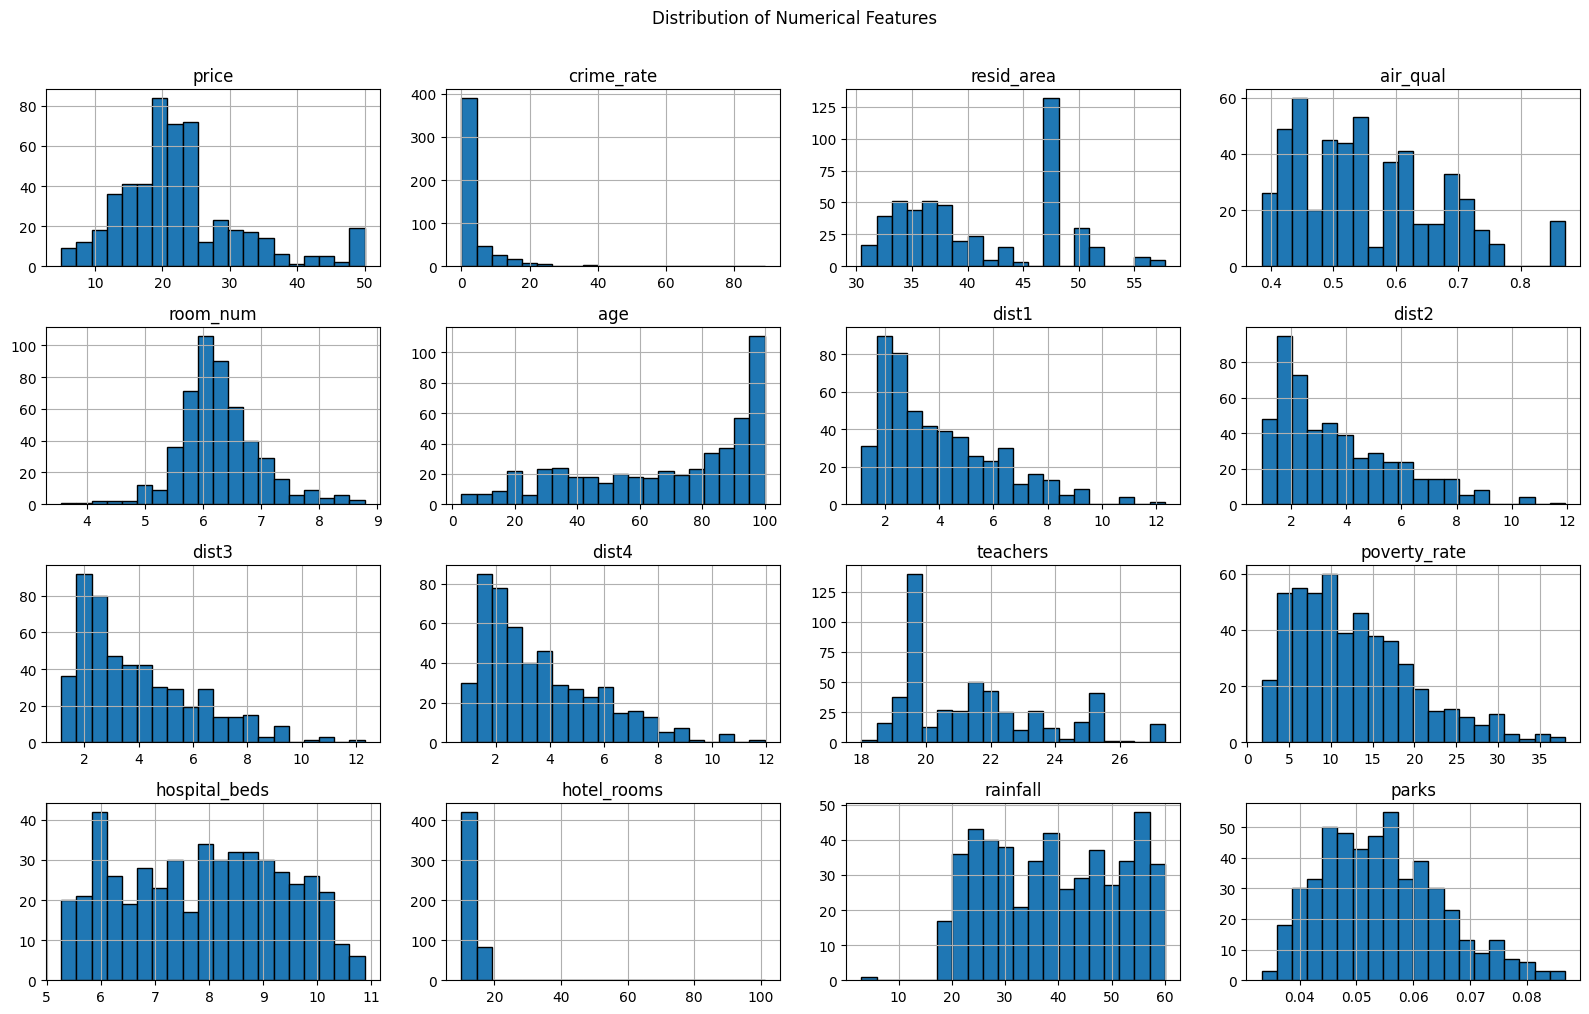

In [7]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

df[num_cols].hist(figsize=(16, 10), bins=20, edgecolor='black')
plt.suptitle('Distribution of Numerical Features', y=1.01)
plt.tight_layout()
plt.show()

### 5b. Categorical Features — Bar Charts

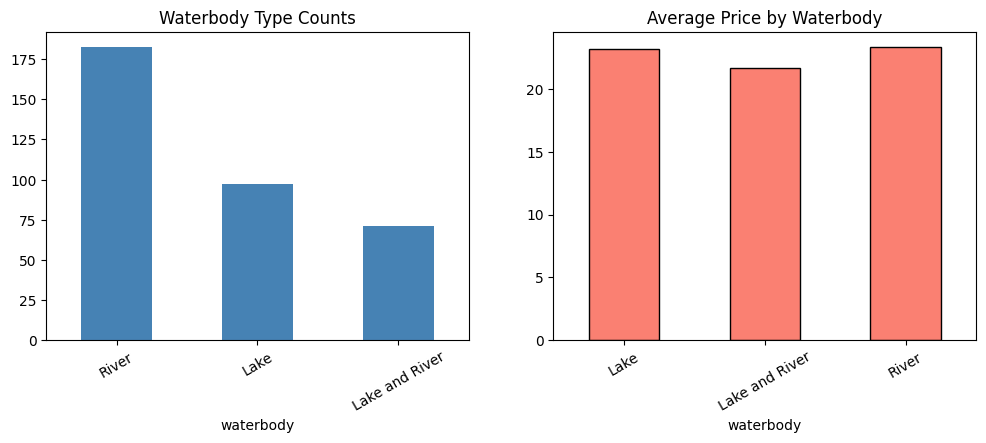

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['waterbody'].value_counts().plot.bar(
    ax=axes[0], color='steelblue')
axes[0].set_title('Waterbody Type Counts')
axes[0].tick_params(axis='x', rotation=30)

df.groupby('waterbody')['price'].mean().plot.bar(
    ax=axes[1], color='salmon', edgecolor='k')
axes[1].set_title('Average Price by Waterbody')
axes[1].tick_params(axis='x', rotation=30)

plt.show()

## 6. Train / Test Split

- `test_size=0.2` → 80 % train, 20 % test (a common default).  
- `random_state=1` → reproducible results.  
- **Preprocess after splitting** to prevent data leakage.

In [9]:
# Define features and target
X = df.drop(columns='price')
y = df['price']
X

,crime_rate,resid_area,air_qual,room_num,age,dist1,dist2,dist3,dist4,teachers,poverty_rate,airport,hospital_beds,hotel_rooms,waterbody,rainfall,has_bus_terminal,parks
0,0.00632,32.31,0.538,6.575,65.2,4.35,3.81,4.18,4.01,24.7,4.98,YES,5.480,11.1920,River,23,YES,0.049347
1,0.02731,37.07,0.469,6.421,78.9,4.99,4.70,5.12,5.06,22.2,9.14,NO,7.332,12.1728,Lake,42,YES,0.046146
2,0.02729,37.07,0.469,7.185,61.1,5.03,4.86,5.01,4.97,22.2,4.03,NO,7.394,101.1200,NaN,38,YES,0.045764
3,0.03237,32.18,0.458,6.998,45.8,6.21,5.93,6.16,5.96,21.3,2.94,YES,9.268,11.2672,Lake,45,YES,0.047151
4,0.06905,32.18,0.458,7.147,54.2,6.16,5.86,6.37,5.86,21.3,5.33,NO,8.824,11.2896,Lake,55,YES,0.039474
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,41.93,0.573,6.593,69.1,2.64,2.45,2.76,2.06,19.0,9.67,NO,9.348,12.1792,Lake and River,27,YES,0.056006
502,0.04527,41.93,0.573,6.120,76.7,2.44,2.11,2.46,2.14,19.0,9.08,YES,6.612,13.1648,Lake and River,20,YES,0.059903
503,0.06076,41.93,0.573,6.976,91.0,2.34,2.06,2.29,1.98,19.0,5.64,NO,5.478,12.1912,NaN,31,YES,0.057572
504,0.10959,41.93,0.573,6.794,89.3,2.54,2.31,2.40,2.31,19.0,6.48,YES,7.940,15.1760,NaN,47,YES,0.060694


In [10]:
print(f'Features: {X.shape[1]}  |  Samples: {X.shape[0]}')

Features: 18  |  Samples: 506


In [11]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

print(f'Train: {x_train.shape}  |  Test: {x_test.shape}')

Train: (404, 18)  |  Test: (102, 18)


## 7. Handling Missing Values
Three strategies:
- **Drop** — if a column has too many missing values.
- **Impute** — fill with mean / median / mode / a constant.
- **Flag** — when missing value itself is informative.

In [12]:
# Numerical columns: impute with median (robust to outliers)
numeric_cols = x_train.select_dtypes(include=np.number).columns.tolist()
numeric_imputer = SimpleImputer(strategy='median')

x_train[numeric_cols] = numeric_imputer.fit_transform(x_train[numeric_cols])
x_test[numeric_cols] = numeric_imputer.transform(x_test[numeric_cols])

In [13]:
# Categorical column: impute with mode
categorical_imputer = SimpleImputer(strategy='most_frequent')

x_train[['waterbody']] = categorical_imputer.fit_transform(x_train[['waterbody']])
x_test[['waterbody']] = categorical_imputer.transform(x_test[['waterbody']])

In [14]:
x_train.head()

,crime_rate,resid_area,air_qual,room_num,age,dist1,dist2,dist3,dist4,teachers,poverty_rate,airport,hospital_beds,hotel_rooms,waterbody,rainfall,has_bus_terminal,parks
42,0.14150,36.91,0.448,6.169,6.6,5.93,5.46,5.88,5.62,22.1,5.81,NO,8.106,15.2024,River,52.0,YES,0.041830
58,0.15445,35.13,0.453,6.145,29.2,7.98,7.77,8.07,7.44,20.3,6.86,NO,7.866,14.1864,River,22.0,YES,0.043784
385,16.81180,48.10,0.700,5.277,98.1,1.46,1.23,1.62,1.40,19.8,30.81,NO,10.144,13.0576,Lake and River,36.0,YES,0.059991
78,0.05646,42.83,0.437,6.232,53.7,5.34,5.00,5.10,4.62,21.3,12.34,YES,8.824,15.1696,Lake,53.0,YES,0.037647
424,8.79212,48.10,0.584,5.565,70.6,2.26,1.99,2.38,1.63,19.8,17.16,NO,7.834,11.0936,River,57.0,YES,0.063779


In [15]:
# Confirm
print('Remaining missing values in train:', x_train.isnull().sum().sum())
print('Remaining missing values in test:', x_test.isnull().sum().sum())

Remaining missing values in train: 0
Remaining missing values in test: 0


### Alternative: KNN Imputer
`KNNImputer` fills missing values using the k nearest neighbours — smarter than a simple mean/median when features are correlated.

In [16]:
# Demonstration only (apply to a copy)
df_knn = df.select_dtypes(include=np.number).copy()
df_knn.iloc[0, 2] = np.nan   # artificially introduce a NaN
df_knn.iloc[1, 2] = np.nan
df_knn.iloc[2, 2] = np.nan
df_knn.iloc[3, 2] = np.nan
df_knn

,price,crime_rate,resid_area,air_qual,room_num,age,dist1,dist2,dist3,dist4,teachers,poverty_rate,hospital_beds,hotel_rooms,rainfall,parks
0,24.0,0.00632,NaN,0.538,6.575,65.2,4.35,3.81,4.18,4.01,24.7,4.98,5.480,11.1920,23,0.049347
1,21.6,0.02731,NaN,0.469,6.421,78.9,4.99,4.70,5.12,5.06,22.2,9.14,7.332,12.1728,42,0.046146
2,34.7,0.02729,NaN,0.469,7.185,61.1,5.03,4.86,5.01,4.97,22.2,4.03,7.394,101.1200,38,0.045764
3,33.4,0.03237,NaN,0.458,6.998,45.8,6.21,5.93,6.16,5.96,21.3,2.94,9.268,11.2672,45,0.047151
4,36.2,0.06905,32.18,0.458,7.147,54.2,6.16,5.86,6.37,5.86,21.3,5.33,8.824,11.2896,55,0.039474
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,22.4,0.06263,41.93,0.573,6.593,69.1,2.64,2.45,2.76,2.06,19.0,9.67,9.348,12.1792,27,0.056006
502,20.6,0.04527,41.93,0.573,6.120,76.7,2.44,2.11,2.46,2.14,19.0,9.08,6.612,13.1648,20,0.059903
503,23.9,0.06076,41.93,0.573,6.976,91.0,2.34,2.06,2.29,1.98,19.0,5.64,5.478,12.1912,31,0.057572
504,22.0,0.10959,41.93,0.573,6.794,89.3,2.54,2.31,2.40,2.31,19.0,6.48,7.940,15.1760,47,0.060694


In [17]:
knn_imputer = KNNImputer(n_neighbors=5)

x_train_knn_filled = pd.DataFrame(
    knn_imputer.fit_transform(x_train[numeric_cols]),
    columns=numeric_cols,
    index=x_train.index  # Preserves original row indices
)

x_test_knn_filled = pd.DataFrame(
    knn_imputer.transform(x_test[numeric_cols]),
    columns=numeric_cols,
    index=x_test.index
)

print('x_train missing numerical values:', x_train_knn_filled.isnull().sum().sum())
print('x_test missing numerical values:', x_test_knn_filled.isnull().sum().sum())

x_train missing numerical values: 0
x_test missing numerical values: 0


In [18]:
x_train_knn_filled

,crime_rate,resid_area,air_qual,room_num,age,dist1,dist2,dist3,dist4,teachers,poverty_rate,hospital_beds,hotel_rooms,rainfall,parks
42,0.14150,36.91,0.448,6.169,6.6,5.93,5.46,5.88,5.62,22.1,5.81,8.106,15.2024,52.0,0.041830
58,0.15445,35.13,0.453,6.145,29.2,7.98,7.77,8.07,7.44,20.3,6.86,7.866,14.1864,22.0,0.043784
385,16.81180,48.10,0.700,5.277,98.1,1.46,1.23,1.62,1.40,19.8,30.81,10.144,13.0576,36.0,0.059991
78,0.05646,42.83,0.437,6.232,53.7,5.34,5.00,5.10,4.62,21.3,12.34,8.824,15.1696,53.0,0.037647
424,8.79212,48.10,0.584,5.565,70.6,2.26,1.99,2.38,1.63,19.8,17.16,7.834,11.0936,57.0,0.063779
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255,0.03548,33.64,0.392,5.876,19.1,9.23,9.11,9.48,9.06,23.6,9.25,7.818,15.1672,31.0,0.043736
72,0.09164,40.81,0.413,6.065,7.8,5.46,4.96,5.61,5.12,20.8,5.52,5.856,10.1824,20.0,0.036089
396,5.87205,48.10,0.693,6.405,96.0,1.77,1.64,1.80,1.49,19.8,19.37,5.450,11.1000,24.0,0.068463
235,0.33045,36.20,0.507,6.086,61.5,3.91,3.39,3.81,3.49,22.6,10.88,9.180,14.1920,57.0,0.052493


## 8. Outlier Detection & Treatment
Outliers can distort model training. Two common detection methods:
- **IQR method** — flag values outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR].

IQR outliers in price (y_train): 28


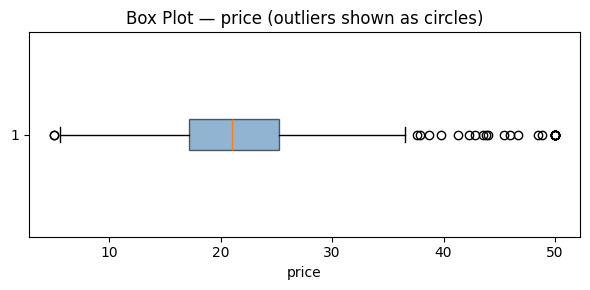

In [19]:
Q1  = y_train.quantile(0.25)
Q3  = y_train.quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

# Filter outliers strictly from training target
outliers_iqr = y_train[(y_train < lower) | (y_train > upper)]
print(f'IQR outliers in price (y_train): {len(outliers_iqr)}')

# Visualise with box plot
plt.figure(figsize=(6, 3))
plt.boxplot(y_train, vert=False, patch_artist=True,
            boxprops=dict(facecolor='steelblue', alpha=0.6))
plt.title('Box Plot — price (outliers shown as circles)')
plt.xlabel('price')
plt.tight_layout()
plt.show()

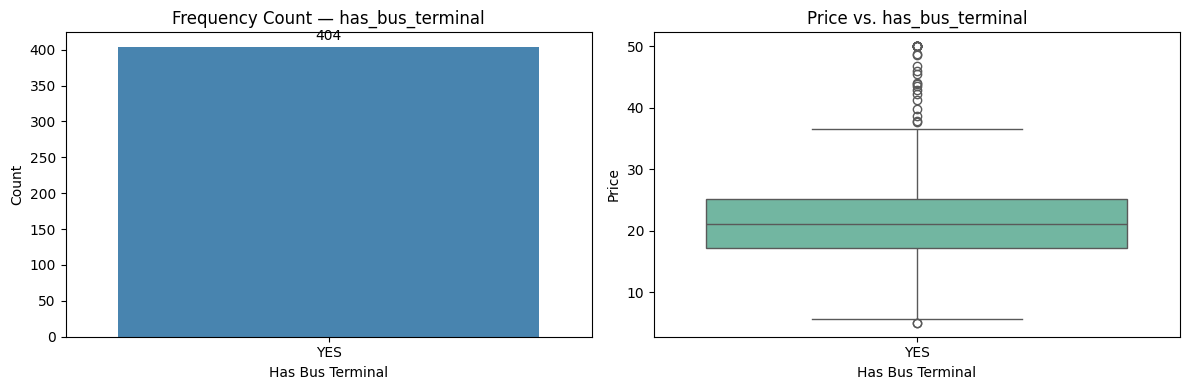

In [20]:
# Combine x_train and y_train temporarily for clean visualization
train_data = pd.concat([x_train, y_train], axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot: Distribution of 'has_bus_terminal' categories
sns.countplot(data=train_data, x='has_bus_terminal', ax=axes[0], palette='Blues_d')
axes[0].set_title('Frequency Count — has_bus_terminal')
axes[0].set_xlabel('Has Bus Terminal')
axes[0].set_ylabel('Count')

# Add values on top of bars
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                     textcoords='offset points')

# Box plot: Impact of 'has_bus_terminal' on 'price'
sns.boxplot(data=train_data, x='has_bus_terminal', y='price', ax=axes[1], palette='Set2')
axes[1].set_title('Price vs. has_bus_terminal')
axes[1].set_xlabel('Has Bus Terminal')
axes[1].set_ylabel('Price')

plt.tight_layout()
plt.show()

## 9. Feature Engineering & Transformations
### Drop Redundant Columns
We drop `has_bus_terminal` — it adds little predictive power.  
We also combine the four distance columns into a single average feature to reduce dimensionality.

In [21]:
# Drop low-value column from feature matrices
x_train.drop(columns=['has_bus_terminal'], inplace=True, errors='ignore')
x_test.drop(columns=['has_bus_terminal'], inplace=True, errors='ignore')

# Combine 4 distance columns → 1 average distance
dist_cols = ['dist1', 'dist2', 'dist3', 'dist4']

x_train['avg_dist'] = x_train[dist_cols].mean(axis=1)
x_train.drop(columns=dist_cols, inplace=True)

x_test['avg_dist'] = x_test[dist_cols].mean(axis=1)
x_test.drop(columns=dist_cols, inplace=True)

# Print updated feature shapes
print(f'x_train shape after feature engineering: {x_train.shape}')
print(f'x_test shape after feature engineering:  {x_test.shape}')

x_train shape after feature engineering: (404, 14)
x_test shape after feature engineering:  (102, 14)


## 10. Encoding Categorical Variables
### 10a. One-Hot Encoding
Creates a binary column per category. Use when there is **no ordinal relationship** between categories.

In [22]:
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

train_enc = enc.fit_transform(x_train[['waterbody']])
test_enc  = enc.transform(x_test[['waterbody']])

In [23]:
ohe_cols = enc.get_feature_names_out(['waterbody'])

In [24]:
train_ohe = pd.DataFrame(
    train_enc,
    columns=ohe_cols,
    index=x_train.index
)

test_ohe = pd.DataFrame(
    test_enc,
    columns=ohe_cols,
    index=x_test.index
)

In [25]:
train_ohe

,waterbody_Lake,waterbody_Lake and River,waterbody_River
42,0.0,0.0,1.0
58,0.0,0.0,1.0
385,0.0,1.0,0.0
78,1.0,0.0,0.0
424,0.0,0.0,1.0
...,...,...,...
255,0.0,0.0,1.0
72,0.0,0.0,1.0
396,0.0,0.0,1.0
235,0.0,0.0,1.0


In [26]:
train_final = pd.concat(
    [x_train.drop(['waterbody'], axis=1),
     train_ohe],
    axis=1
)

test_final = pd.concat(
    [x_test.drop(['waterbody'], axis=1),
     test_ohe],
    axis=1
)

In [27]:
train_final.head()

,crime_rate,resid_area,air_qual,room_num,age,teachers,poverty_rate,airport,hospital_beds,hotel_rooms,rainfall,parks,avg_dist,waterbody_Lake,waterbody_Lake and River,waterbody_River
42,0.14150,36.91,0.448,6.169,6.6,22.1,5.81,NO,8.106,15.2024,52.0,0.041830,5.7225,0.0,0.0,1.0
58,0.15445,35.13,0.453,6.145,29.2,20.3,6.86,NO,7.866,14.1864,22.0,0.043784,7.8150,0.0,0.0,1.0
385,16.81180,48.10,0.700,5.277,98.1,19.8,30.81,NO,10.144,13.0576,36.0,0.059991,1.4275,0.0,1.0,0.0
78,0.05646,42.83,0.437,6.232,53.7,21.3,12.34,YES,8.824,15.1696,53.0,0.037647,5.0150,1.0,0.0,0.0
424,8.79212,48.10,0.584,5.565,70.6,19.8,17.16,NO,7.834,11.0936,57.0,0.063779,2.0650,0.0,0.0,1.0


### 10b. Ordinal Encoding
Maps each category to an integer. Useful for **ordinal** data or tree-based models.  

In [28]:
# Create Sample Dataset
data = {
    'condition': ['Poor', 'Fair', 'Good', 'Excellent', 'Fair', 'Good', 'Poor', 'Excellent'],  # Ranked (Ordinal)
    'waterbody': ['None', 'River', 'Lake', 'None', 'Lake', 'River', 'None', 'Lake'],        # Unranked (Nominal)
    'square_feet': [1200, 1500, 1800, 2400, 1400, 1900, 1100, 2600],
    'price': [150, 200, 280, 400, 190, 310, 130, 450]  # Target (y)
}

df = pd.DataFrame(data)

# Separate features (X) and target (y)
X = df.drop(columns='price')
y = df['price']

# Train/Test Split FIRST
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Make explicit copies to avoid Pandas warnings
x_train = x_train.copy()
x_test = x_test.copy()

print("--- Original x_train ---")
print(x_train[['condition', 'waterbody']])
print("\n" + "="*50 + "\n")


# --- Ordinal Encoding ('condition') ---
# Define explicit hierarchy: Poor (0) < Fair (1) < Good (2) < Excellent (3)
condition_levels = [['Poor', 'Fair', 'Good', 'Excellent']]

ord_encoder = OrdinalEncoder(categories=condition_levels)

# Fit on train, transform on both
x_train['condition_encoded'] = ord_encoder.fit_transform(x_train[['condition']])
x_test['condition_encoded'] = ord_encoder.transform(x_test[['condition']])


# --- One-Hot Encoding ('waterbody') ---
# No natural rank -> create binary dummy columns
ohe_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# Fit on train, transform on both
train_waterbody_ohe = ohe_encoder.fit_transform(x_train[['waterbody']])
test_waterbody_ohe = ohe_encoder.transform(x_test[['waterbody']])

# Convert NumPy arrays back to DataFrames with proper column names
ohe_feature_names = ohe_encoder.get_feature_names_out(['waterbody'])

train_ohe_df = pd.DataFrame(train_waterbody_ohe, columns=ohe_feature_names, index=x_train.index)
test_ohe_df = pd.DataFrame(test_waterbody_ohe, columns=ohe_feature_names, index=x_test.index)

# Merge back into main feature matrices
x_train = pd.concat([x_train, train_ohe_df], axis=1)
x_test = pd.concat([x_test, test_ohe_df], axis=1)


# Drop raw categorical text columns
x_train.drop(columns=['condition', 'waterbody'], inplace=True)
x_test.drop(columns=['condition', 'waterbody'], inplace=True)

print("--- Encoded x_train ---")
print(x_train)

print("\n--- Encoded x_test ---")
print(x_test)

--- Original x_train ---
   condition waterbody
0       Poor      None
7  Excellent      Lake
2       Good      Lake
4       Fair      Lake
3  Excellent      None
6       Poor      None


--- Encoded x_train ---
   square_feet  condition_encoded  waterbody_Lake  waterbody_None
0         1200                0.0             0.0             1.0
7         2600                3.0             1.0             0.0
2         1800                2.0             1.0             0.0
4         1400                1.0             1.0             0.0
3         2400                3.0             0.0             1.0
6         1100                0.0             0.0             1.0

--- Encoded x_test ---
   square_feet  condition_encoded  waterbody_Lake  waterbody_None
1         1500                1.0             0.0             0.0
5         1900                2.0             0.0             0.0


## 11. From Notebook Steps to One ML Pipeline
Every preprocessing step above becomes one object that is fitted on train data only and shipped together with the model.

```
raw house ──► engineer_features ──► ColumnTransformer ───────────────────────► model ──► price
              (avg_dist, drop cols)  ├─ numeric   : impute(median) → scale
                                     ├─ waterbody : impute(mode)   → one-hot
                                     └─ airport   : impute(mode)   → one-hot
```

### 11a. Reload the Raw Data
Section 10b overwrote `df`, `X` and the splits with toy data, so we start again from the CSV.

In [29]:
df = pd.read_csv('/content/House_Price.csv')
df.rename(columns={
    'n_hos_beds':  'hospital_beds',
    'n_hot_rooms': 'hotel_rooms',
    'poor_prop':   'poverty_rate',
    'bus_ter':     'has_bus_terminal',
}, inplace=True)

X = df.drop(columns='price')
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)
print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')

Train: (404, 18)  |  Test: (102, 18)


### 11b. Feature Engineering as a Module
Custom code lives in a `.py` file so the saved model can be loaded later by the API.

In [30]:
%%writefile house_features.py
import numpy as np
import pandas as pd

DIST_COLS = ['dist1', 'dist2', 'dist3', 'dist4']
DROP_COLS = DIST_COLS + ['has_bus_terminal']


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Same feature engineering as Section 9, applied to raw input."""
    df = df.copy()
    df = df.where(df.notna(), np.nan)          # None (from JSON) -> NaN
    df['avg_dist'] = df[DIST_COLS].astype(float).mean(axis=1)
    return df.drop(columns=DROP_COLS, errors='ignore')


Writing house_features.py


In [31]:
from house_features import engineer_features

engineer_features(X_train).head()

,crime_rate,resid_area,air_qual,room_num,age,teachers,poverty_rate,airport,hospital_beds,hotel_rooms,waterbody,rainfall,parks,avg_dist
42,0.14150,36.91,0.448,6.169,6.6,22.1,5.81,NO,8.106,15.2024,River,52,0.041830,5.7225
58,0.15445,35.13,0.453,6.145,29.2,20.3,6.86,NO,7.866,14.1864,NaN,22,0.043784,7.8150
385,16.81180,48.10,0.700,5.277,98.1,19.8,30.81,NO,10.144,13.0576,Lake and River,36,0.059991,1.4275
78,0.05646,42.83,0.437,6.232,53.7,21.3,12.34,YES,8.824,15.1696,Lake,53,0.037647,5.0150
424,8.79212,48.10,0.584,5.565,70.6,19.8,17.16,NO,7.834,11.0936,NaN,57,0.063779,2.0650


### 11c. Build the Preprocessor

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.base import clone
from sklearn import set_config

set_config(display='diagram')

numeric_features = ['crime_rate', 'resid_area', 'air_qual', 'room_num', 'age',
                    'teachers', 'poverty_rate', 'hospital_beds', 'hotel_rooms',
                    'rainfall', 'parks', 'avg_dist']

numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale',  StandardScaler()),
])
waterbody_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
airport_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='if_binary', sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num',       numeric_pipe,   numeric_features),
    ('waterbody', waterbody_pipe, ['waterbody']),
    ('airport',   airport_pipe,   ['airport']),
])


def build_pipeline(model):
    """Raw DataFrame in → prediction out."""
    return Pipeline([
        ('features',   FunctionTransformer(engineer_features)),
        ('preprocess', clone(preprocessor)),
        ('model',      model),
    ])

In [33]:
from sklearn.linear_model import LinearRegression

build_pipeline(LinearRegression())

Pipeline(steps=[('features',
                 FunctionTransformer(func=<function engineer_features at 0x7b753c1f4180>)),
                ('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['crime_rate', 'resid_area',
                                                   'air_qual', 'room_num',
                                                   'age', 'teachers',
                                                   'poverty_rate',
                                                   'hospital_beds',
                                                   'hotel_rooms...
                                                 ('waterbody',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['waterbody']),
                                                 ('airport',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(drop='if_binary',
                                                                                 sparse_output=False))]),
                                                  ['airport'])])),
                ('model', LinearRegression())])

## 12. Model Training

```
Train set ──► 5-fold CV (compare models) ──► GridSearchCV (tune best) ──► fit on full train ──► Test set (once)
```

### 12a. Baseline
Any real model must beat "always predict the mean price".

In [34]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaluate(pipe, X, y):
    pred = pipe.predict(X)
    return {
        'MAE':  mean_absolute_error(y, pred),
        'RMSE': float(np.sqrt(mean_squared_error(y, pred))),
        'R2':   r2_score(y, pred),
    }


baseline = build_pipeline(DummyRegressor(strategy='mean')).fit(X_train, y_train)
baseline_scores = evaluate(baseline, X_test, y_test)
baseline_scores

{'MAE': 6.906639487478158,
 'RMSE': 9.94136104209215,
 'R2': -3.308701823501181e-05}

### 12b. Compare Models with Cross-Validation
The test set stays untouched; models are compared on 5 train/validation folds.

In [35]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=1)

candidates = {
    'Linear Regression': LinearRegression(),
    'Ridge':             Ridge(alpha=1.0),
    'Random Forest':     RandomForestRegressor(n_estimators=300, random_state=1, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=1),
}

rows = []
for name, model in candidates.items():
    scores = cross_validate(build_pipeline(model), X_train, y_train, cv=cv,
                            scoring=['neg_root_mean_squared_error', 'r2'])
    rmse = -scores['test_neg_root_mean_squared_error']
    rows.append({'model': name,
                 'cv_rmse': rmse.mean(),
                 'cv_rmse_std': rmse.std(),
                 'cv_r2': scores['test_r2'].mean()})

cv_results = pd.DataFrame(rows).sort_values('cv_rmse').reset_index(drop=True)
cv_results.round(3)

,model,cv_rmse,cv_rmse_std,cv_r2
0,Gradient Boosting,3.274,0.170,0.853
1,Random Forest,3.409,0.473,0.839
2,Ridge,5.440,0.912,0.586
3,Linear Regression,5.445,0.910,0.585


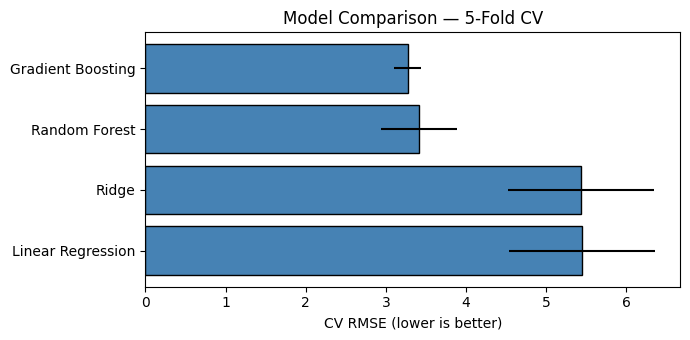

In [36]:
plt.figure(figsize=(7, 3.5))
plt.barh(cv_results['model'], cv_results['cv_rmse'],
         xerr=cv_results['cv_rmse_std'], color='steelblue', edgecolor='k')
plt.gca().invert_yaxis()
plt.xlabel('CV RMSE (lower is better)')
plt.title('Model Comparison — 5-Fold CV')
plt.tight_layout()
plt.show()

### 12c. Hyperparameter Tuning
Tune only the winner from 12b; `model__` targets the last step of the pipeline.

In [37]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    'Linear Regression': {},
    'Ridge':             {'model__alpha': [0.1, 1, 10, 100]},
    'Random Forest':     {'model__n_estimators': [200, 400],
                          'model__max_depth': [None, 10],
                          'model__min_samples_leaf': [1, 2]},
    'Gradient Boosting': {'model__n_estimators': [200, 400],
                          'model__learning_rate': [0.05, 0.1],
                          'model__max_depth': [2, 3]},
}

best_name = cv_results.loc[0, 'model']
search = GridSearchCV(build_pipeline(candidates[best_name]),
                      param_grid=param_grids[best_name],
                      cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
search.fit(X_train, y_train)

best_pipeline = search.best_estimator_
print('Best model :', best_name)
print('Best params:', search.best_params_)
print(f'CV RMSE    : {-search.best_score_:.3f}')

Best model : Gradient Boosting
Best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 400}
CV RMSE    : 3.245


### 12d. Final Evaluation on the Test Set
The test set is used exactly once, after all choices are made.

In [38]:
test_scores = evaluate(best_pipeline, X_test, y_test)

pd.DataFrame({'Baseline (mean)': baseline_scores,
              best_name:         test_scores}).T.round(3)

,MAE,RMSE,R2
Baseline (mean),6.907,9.941,-0.000
Gradient Boosting,2.163,2.996,0.909


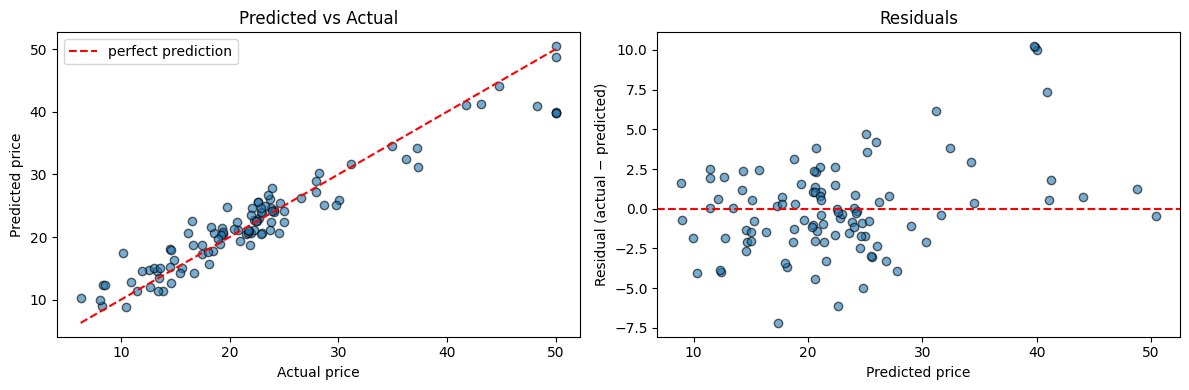

In [39]:
y_pred = best_pipeline.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, y_pred, alpha=0.6, edgecolor='k')
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, 'r--', label='perfect prediction')
axes[0].set_xlabel('Actual price')
axes[0].set_ylabel('Predicted price')
axes[0].set_title('Predicted vs Actual')
axes[0].legend()

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.6, edgecolor='k')
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel('Predicted price')
axes[1].set_ylabel('Residual (actual − predicted)')
axes[1].set_title('Residuals')

plt.tight_layout()
plt.show()

### 12e. Feature Importance

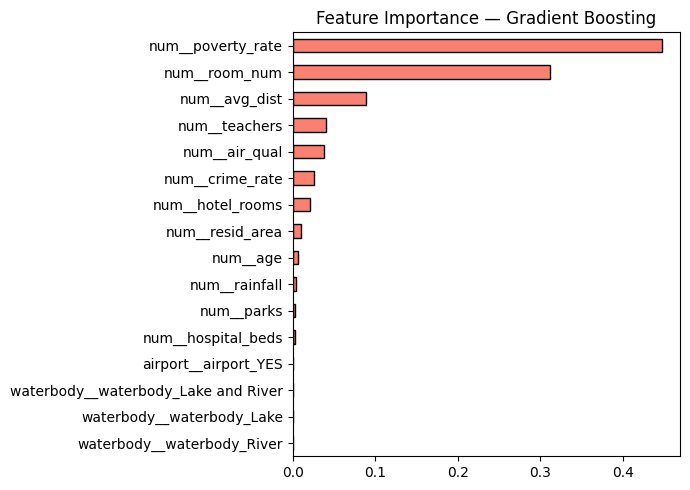

In [40]:
feature_names = best_pipeline.named_steps['preprocess'].get_feature_names_out()
final_model   = best_pipeline.named_steps['model']

if hasattr(final_model, 'feature_importances_'):
    importance = final_model.feature_importances_
else:                                          # linear models
    importance = np.abs(final_model.coef_)

imp = pd.Series(importance, index=feature_names).sort_values()

imp.plot.barh(figsize=(7, 5), color='salmon', edgecolor='k')
plt.title(f'Feature Importance — {best_name}')
plt.tight_layout()
plt.show()

## 13. Deployment

```
client ──HTTP POST (JSON)──► FastAPI (app.py) ──► model.joblib (full pipeline) ──► {"predicted_price": ...}
```

### 13a. Save the Model Artifact
Save the whole pipeline plus metadata, in a versioned folder.

In [41]:
import json
import joblib
import sklearn
from pathlib import Path
from datetime import datetime, timezone

MODEL_VERSION = 'v1'
artifact_dir = Path(f'artifacts/house_price_{MODEL_VERSION}')
artifact_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(best_pipeline, artifact_dir / 'model.joblib')

metadata = {
    'version':        MODEL_VERSION,
    'model':          best_name,
    'params':         {k: str(v) for k, v in search.best_params_.items()},
    'test_metrics':   {k: round(float(v), 3) for k, v in test_scores.items()},
    'input_features': list(X_train.columns),
    'trained_at':     datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'sklearn':        sklearn.__version__,
}
(artifact_dir / 'metadata.json').write_text(json.dumps(metadata, indent=2))

print(json.dumps(metadata, indent=2))

{
  "version": "v1",
  "model": "Gradient Boosting",
  "params": {
    "model__learning_rate": "0.05",
    "model__max_depth": "3",
    "model__n_estimators": "400"
  },
  "test_metrics": {
    "MAE": 2.163,
    "RMSE": 2.996,
    "R2": 0.909
  },
  "input_features": [
    "crime_rate",
    "resid_area",
    "air_qual",
    "room_num",
    "age",
    "dist1",
    "dist2",
    "dist3",
    "dist4",
    "teachers",
    "poverty_rate",
    "airport",
    "hospital_beds",
    "hotel_rooms",
    "waterbody",
    "rainfall",
    "has_bus_terminal",
    "parks"
  ],
  "trained_at": "2026-10-14T22:57:36+00:00",
  "sklearn": "1.6.1"
}


### 13b. Load and Predict on a Raw Input
The loaded pipeline accepts raw values, including missing ones, exactly like a real request.

In [42]:
loaded = joblib.load(artifact_dir / 'model.joblib')

new_house = {
    'crime_rate': 0.03, 'resid_area': 37.07, 'air_qual': 0.47, 'room_num': 6.5,
    'age': 60.0, 'dist1': 4.9, 'dist2': 4.7, 'dist3': 5.0, 'dist4': 4.9,
    'teachers': 22.0, 'poverty_rate': 6.0, 'airport': 'YES',
    'hospital_beds': None,                 # missing → imputed by the pipeline
    'hotel_rooms': 12.0, 'waterbody': None, # missing → imputed by the pipeline
    'rainfall': 40, 'has_bus_terminal': 'YES', 'parks': 0.05,
}

pred = loaded.predict(pd.DataFrame([new_house]))[0]
print(f'Predicted price: {pred:.2f}')

Predicted price: 24.17


### 13c. Write the API

In [43]:
!pip install -q fastapi uvicorn

In [44]:
%%writefile app.py
import json
from pathlib import Path
from typing import List, Literal, Optional

import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel, Field

ARTIFACT_DIR = Path('artifacts/house_price_v1')
model = joblib.load(ARTIFACT_DIR / 'model.joblib')
metadata = json.loads((ARTIFACT_DIR / 'metadata.json').read_text())

app = FastAPI(title='House Price API', version=metadata['version'])


class House(BaseModel):
    crime_rate: float = Field(ge=0)
    resid_area: float
    air_qual: float
    room_num: float = Field(gt=0)
    age: float = Field(ge=0, le=100)
    dist1: float
    dist2: float
    dist3: float
    dist4: float
    teachers: float
    poverty_rate: float
    airport: Literal['YES', 'NO']
    hospital_beds: Optional[float] = None
    hotel_rooms: float
    waterbody: Optional[Literal['Lake', 'River', 'Lake and River']] = None
    rainfall: float
    has_bus_terminal: Literal['YES', 'NO'] = 'YES'
    parks: float


@app.get('/health')
def health():
    return {'status': 'ok'}


@app.get('/model-info')
def model_info():
    return metadata


@app.post('/predict')
def predict(house: House):
    X = pd.DataFrame([house.model_dump()])
    price = float(model.predict(X)[0])
    return {'predicted_price': round(price, 2), 'model_version': metadata['version']}


@app.post('/predict/batch')
def predict_batch(houses: List[House]):
    X = pd.DataFrame([h.model_dump() for h in houses])
    prices = model.predict(X)
    return {'predicted_prices': [round(float(p), 2) for p in prices],
            'model_version': metadata['version']}


Writing app.py


### 13d. Run the Server
Uvicorn runs the API in the background on port 8000.

In [45]:
import subprocess, sys, time, requests

server = subprocess.Popen(
    [sys.executable, '-m', 'uvicorn', 'app:app', '--host', '127.0.0.1', '--port', '8000'],
    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
)

BASE_URL = 'http://127.0.0.1:8000'
for _ in range(30):                     # wait until the server is up
    try:
        if requests.get(f'{BASE_URL}/health', timeout=1).ok:
            break
    except requests.ConnectionError:
        time.sleep(1)

requests.get(f'{BASE_URL}/health').json()

{'status': 'ok'}

### 13e. Call the API

In [46]:
requests.get(f'{BASE_URL}/model-info').json()

{'version': 'v1',
 'model': 'Gradient Boosting',
 'params': {'model__learning_rate': '0.05',
  'model__max_depth': '3',
  'model__n_estimators': '400'},
 'test_metrics': {'MAE': 2.163, 'RMSE': 2.996, 'R2': 0.909},
 'input_features': ['crime_rate',
  'resid_area',
  'air_qual',
  'room_num',
  'age',
  'dist1',
  'dist2',
  'dist3',
  'dist4',
  'teachers',
  'poverty_rate',
  'airport',
  'hospital_beds',
  'hotel_rooms',
  'waterbody',
  'rainfall',
  'has_bus_terminal',
  'parks'],
 'trained_at': '2026-10-14T22:57:36+00:00',
 'sklearn': '1.6.1'}

In [47]:
response = requests.post(f'{BASE_URL}/predict', json=new_house)
print(response.status_code)
response.json()

200


{'predicted_price': 24.17, 'model_version': 'v1'}

In [48]:
batch = X_test.head(3).replace({np.nan: None}).to_dict(orient='records')

response = requests.post(f'{BASE_URL}/predict/batch', json=batch)
print('API    :', response.json()['predicted_prices'])

API    : [30.29, 27.82, 18.71]


### 13f. Input Validation
Bad input is rejected with `422` before it ever reaches the model.

In [49]:
bad_house = {**new_house, 'airport': 'MAYBE', 'age': 150}

response = requests.post(f'{BASE_URL}/predict', json=bad_house)
print(response.status_code)
for err in response.json()['detail']:
    print(err['loc'][-1], '→', err['msg'])

422
age → Input should be less than or equal to 100
airport → Input should be 'YES' or 'NO'


### 13g. Stop the Server and Pin Dependencies
A pickled model must be loaded with the same library versions it was trained with.

In [50]:
server.terminate()
server.wait()

import fastapi, uvicorn, pydantic

requirements = (
    f'scikit-learn=={sklearn.__version__}\n'
    f'pandas=={pd.__version__}\n'
    f'numpy=={np.__version__}\n'
    f'joblib=={joblib.__version__}\n'
    f'fastapi=={fastapi.__version__}\n'
    f'uvicorn=={uvicorn.__version__}\n'
    f'pydantic=={pydantic.__version__}\n'
)
Path('requirements.txt').write_text(requirements)
print(requirements)

scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
joblib==1.6.0
fastapi==0.141.1
uvicorn==0.54.0
pydantic==2.13.5



### 13h. Deployable Project
These files are everything a server needs to run the model.

In [51]:
for path in ['app.py', 'house_features.py', 'requirements.txt',
             'artifacts/house_price_v1/model.joblib',
             'artifacts/house_price_v1/metadata.json']:
    size_kb = Path(path).stat().st_size / 1024
    print(f'{path:<42} {size_kb:8.1f} KB')

app.py                                          1.6 KB
house_features.py                               0.5 KB
requirements.txt                                0.1 KB
artifacts/house_price_v1/model.joblib         472.8 KB
artifacts/house_price_v1/metadata.json          0.6 KB
